**Visualizting sound source over phase domain.

The simulation consists of 3 microphones in a line, we simulate the sound each mic receives, apply Hilbert transform to change mechanical wave to an analytical wave, changing from pure real wave to a complex wave, only in the positive plane.

We first determine basic parameters.

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from scipy.io.wavfile import read

# Parameters
f = 3500  # Hz (signal frequency)
c = 343   # m/s (speed of sound)
d = 0.049   # m (mic spacing, lambda/2)
theta = 30 * np.pi / 180  # angle in radians

# Time delay between adjacent mics
tau = (d * np.sin(theta)) / c  # ≈ 0.1457 ms

We read the .wav file, plot, and pull usefull information

Using fs (sampling rate), and no_samples (the length of the file), we determine the duration of the sample.

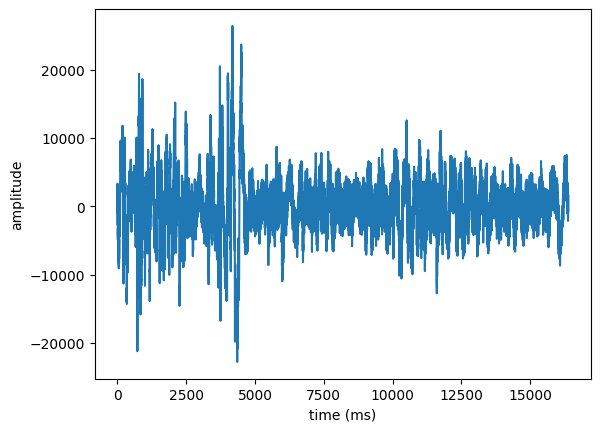

In [51]:
fs, s1 = read('Binary_Drone_Audio_yes_drone_B_S2_D1_067-bebop_000_.wav')
plt.xlabel('time (ms)')
plt.ylabel('amplitude')

plt.plot(s1)

no_samples = len(s1)

duration = no_samples/fs

# Create time vector based on actual signal length
t = np.arange(len(s1)) / fs

Compute the analytical signals and instantaneous phases. Here the array is set up like: s1, s2, s3. Which means we analytic_s2 is the center mic, our reference.

In [52]:
# Compute analytic signals and instantaneous phases
analytic_s2 = hilbert(s1)
analytic_s1 = analytic_s2*np.exp(1j*2*np.pi*f*tau)
analytic_s3 = analytic_s2*np.exp(-1j*2*np.pi*f*tau)

Next, we unwrap the angle for continuity.

In [53]:
# Extract phases (unwrapped for continuity)
phi1 = np.unwrap(np.angle(analytic_s1))
phi2 = np.unwrap(np.angle(analytic_s2))
phi3 = np.unwrap(np.angle(analytic_s3))

Plot time vs. phase.

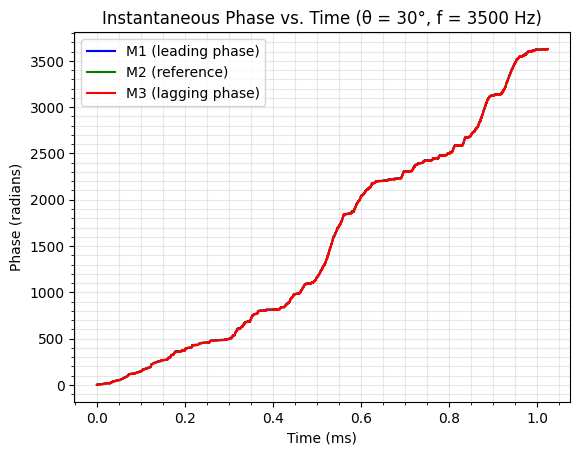

In [54]:
# Plot time vs. phase
plt.xlabel('Time (ms)')
plt.ylabel('Phase (radians)')
plt.title(f'Instantaneous Phase vs. Time (θ = 30°, f = {f} Hz)')
plt.grid(True, which='both', alpha=0.3)
plt.minorticks_on()
plt.plot(t, phi1, label='M1 (leading phase)', color='blue')
plt.plot(t, phi2, label='M2 (reference)', color='green')
plt.plot(t, phi3, label='M3 (lagging phase)', color='red')
plt.legend()

This show that the instantaneous phase of at each microphone is the same, which is what we expect. From here we 

In [55]:
delta_phi1_phi2 = phi1 - phi2
delta_phi3_phi2 = phi3 - phi2

tau12_est = delta_phi1_phi2/(2*np.pi*f)
tau32_est = delta_phi3_phi2/(2*np.pi*f)

theta32_est = np.arcsin(c*tau32_est/d)
theta32_est_deg = theta32_est*180/np.pi

theta12_est = np.arcsin(c*tau12_est/d)
theta12_est_deg = theta12_est*180/np.pi

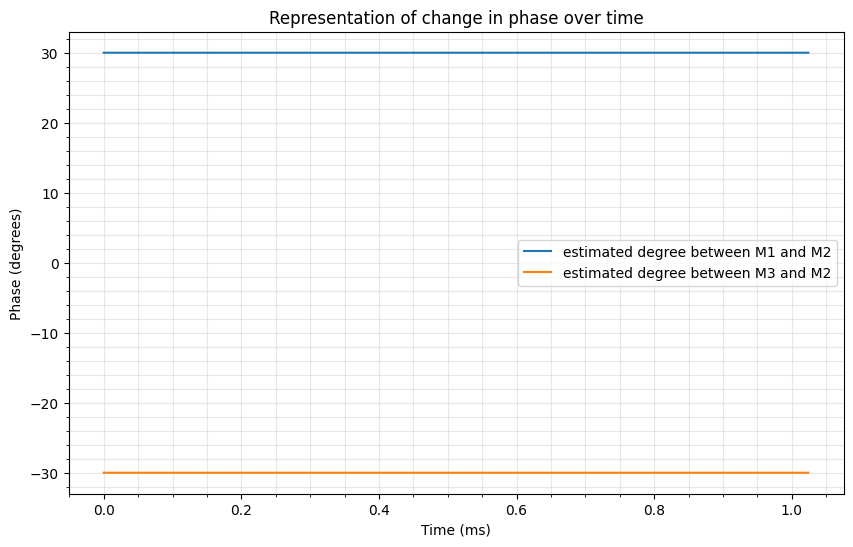

In [56]:
plt.figure(figsize=(10, 6))

plt.xlabel('Time (ms)')
plt.ylabel('Phase (degrees)')
plt.title('Representation of change in phase over time')

plt.plot(t, theta12_est_deg, label = 'estimated degree between M1 and M2')
plt.plot(t, theta32_est_deg, label = 'estimated degree between M3 and M2')

plt.legend()
plt.grid(True, which = 'both', alpha = 0.3)
plt.minorticks_on()




With this plot we have shown that we obtain the correct direciton when we generate the wave using a wav file at each mic. 